In [4]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd
import matplotlib
import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolation_func_V2 import *
import AR_interpolation_func_V2
importlib.reload(AR_interpolation_func_V2)
from AR_interpolation_func_V2  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_plotting import *
import AR_interpolations_plotting
importlib.reload(AR_interpolations_plotting)
from AR_interpolations_plotting  import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Get Simulation data of exctinction spectra for different AR

In [5]:
path1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet'
sample_name = r'\Sapphire'

In [6]:
root_simu = path1 + sample_name + r'\AR_estimation\SPR_simu_treated'
fname_data_simu = 'Simulation_treated.csv'

#kernel = 'thin_plate_spline'
Simu_data, Lda_RBF, E_RBF, W_RBF, Aire_RBF = get_simu_data_and_interpolate(root_simu, fname_data_simu, kernel='linear')

#h_1D = 25


H_lisse = np.linspace(0, 40, 200)
D_lisse = np.linspace(0, 160, 200)
HH_lisse, DD_lisse = np.meshgrid( H_lisse, D_lisse)
points_lisses = np.array(list(zip(HH_lisse.flatten(), DD_lisse.flatten())))

C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\AR_interpolations_plotting.py:30: RuntimeWarning: divide by zero encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)
C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\AR_interpolations_plotting.py:30: RuntimeWarning: invalid value encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)


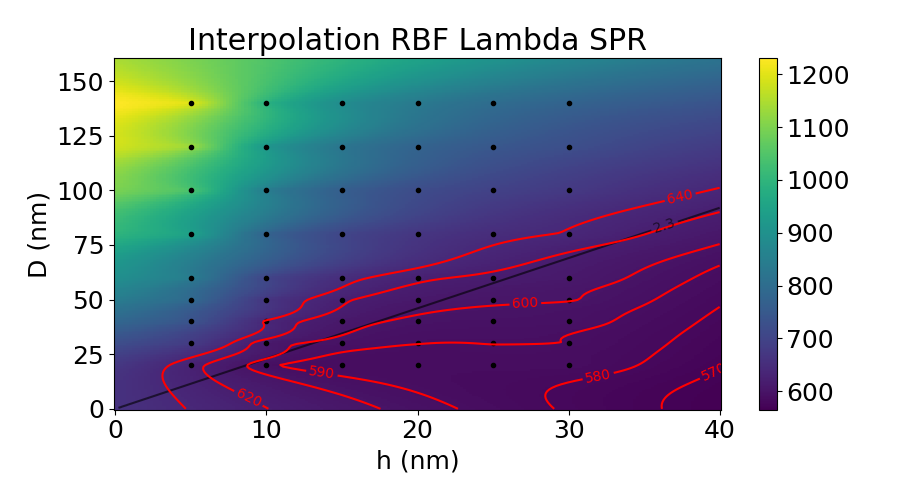

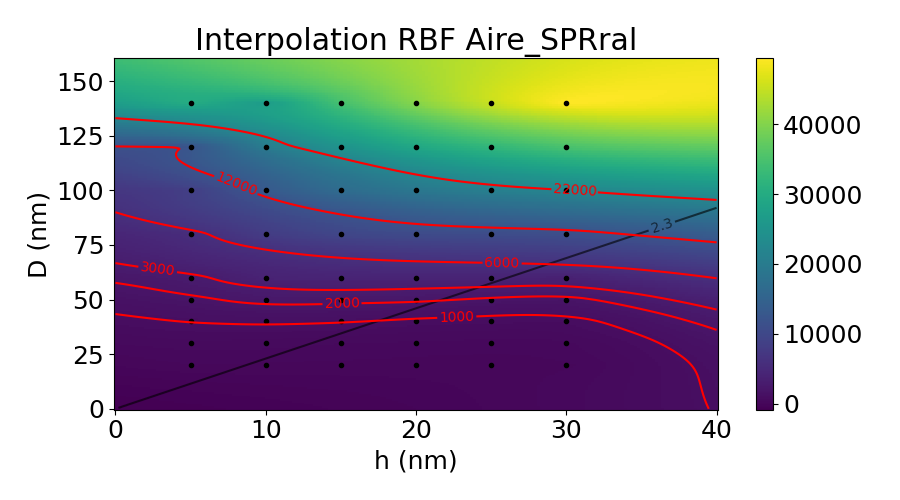

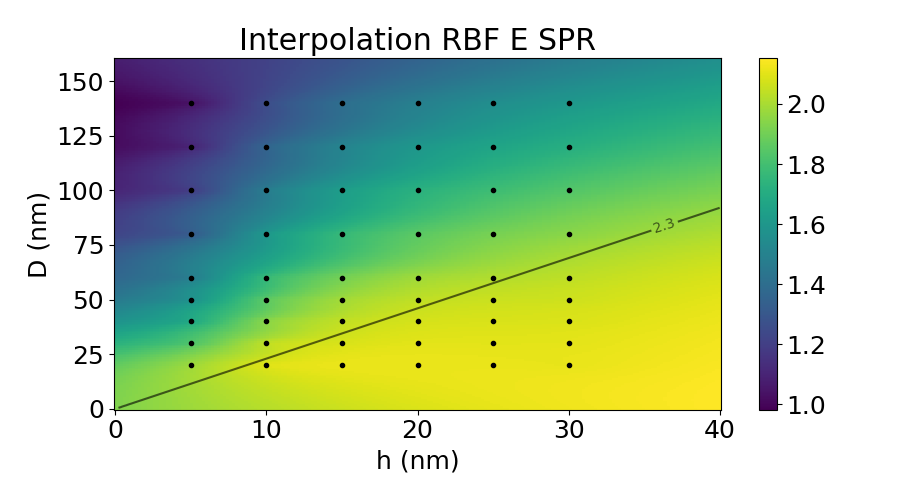

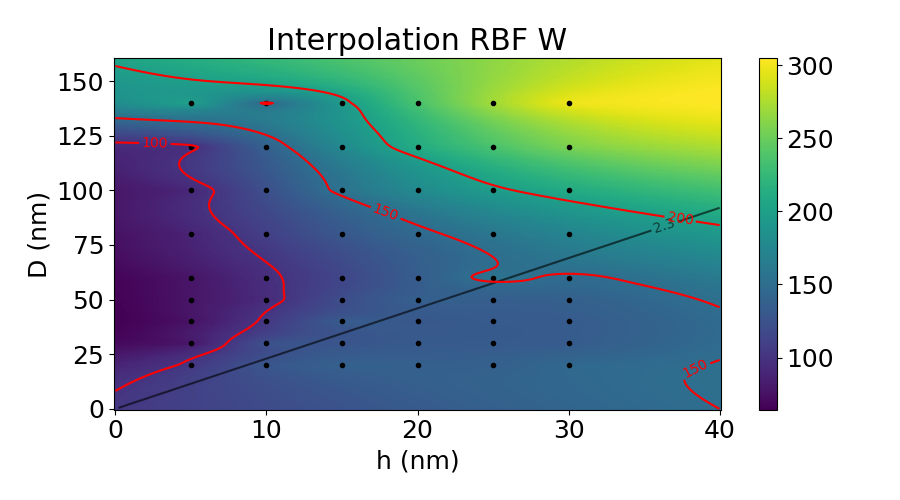

In [7]:
plot_func_interp(Lda_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='Lambda SPR', contour_specif=[570, 580, 590,  600, 620, 640])
plot_func_interp(Aire_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='Aire_SPRral', contour_specif=[1000, 2000, 3000,6000, 12000,22000])
plot_func_interp(E_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='E SPR')
plot_func_interp(W_RBF, H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, Simu_data['points'], title='W', contour_specif=[50, 100, 150, 200])

## Get experimental data of ND

In [8]:
dir_root_ND = path1 + sample_name + r'\AR_estimation\ND_measurements'
fname_Exp = 'Nd_measurements_data.dat'
Exp_data = get_ND_measures(dir_root_ND, fname_Exp)


# for key in Exp_data :
#     print('----------------------------------------------')
#     for kkey in Exp_data[key] :
#         print(kkey, '///',  Exp_data[key][kkey])


## Estimate the AR of experimental data

In [9]:
d_guess, h_guess = 80, 20 #initial (D,h) guess in nm


## Interpolation 1D with Area of SPR
AR_estimation_1D_Aire_SPR(Exp_data, Aire_RBF, h=21)

## Interpolation 2D with Area and position of SPR
AR_estimation_2D(Exp_data, Lda_RBF, Aire_RBF, d_guess=d_guess, h_guess=h_guess)


# Estimate the term Gamma_surf
Gamma_surf_estimation(Exp_data, W_RBF)



Erreur de convergence 2D sur : 2.3 zone-Sylvie NDbs02


## Saving Data

In [10]:
dir_save_data = path1 + sample_name + r'\AR_estimation\ND_measurements_AR_treated'

fname_1D = 'AR_interpolation_results.csv'
save_interpolation_to_csv(Exp_data, dir_save_data, fname_1D)


fname_pickle = 'Treated_data'
save_interpolation_to_data_dic(Exp_data, dir_save_data, fname_pickle)